<!-- m6:deber -->
# Módulo 6 · Deber — Detector bayesiano de fraude para PagoYa
**Diplomado en Big Data e Inteligencia Artificial · CEC-EPN** · Ing. Eduardo Avilés · individual · ≈ 3 horas

**Entrega:** Colab → **Archivo → Guardar (Ctrl+S)** → en *Repositorio* elija **el suyo** → ruta **`deber/deber.ipynb`** → mensaje `Deber`.
**Plazo: domingo 15-nov-2026, 11:00.** Un solo archivo: este cuaderno, ejecutado, con sus respuestas y el informe al final.

**Datos personalizados:** la API simulada genera transacciones **distintas para cada estudiante** a partir de su nombre. Sus cifras no coincidirán con las de sus compañeros; el docente puede regenerar sus datos para verificar.

| Parte | Tema | Puntos |
|---|---|---|
| 1 | Regresión logística bayesiana en PyMC (priors, muestreo y diagnóstico) | 20 |
| 2 | Comparación con boosting (XGBoost): discriminación y calibración | 20 |
| 3 | Modelo jerárquico por provincia | 20 |
| 4 | Decisión con matriz de costos e incertidumbre | 20 |
| 5 | Informe ejecutivo para el comité de riesgos | 20 |
| | **Total** | **100** |

**En cada parte:** código correcto y ejecutado (8) · resultados y diagnósticos (6) · interpretación propia (6).
Aquí no hay `___` para completar: el enunciado guía, **el código lo escribe usted** (puede reutilizar el de las clases 2 y 3).

## 0. Preparación

In [1]:
import importlib, subprocess, sys
for paquete in ['pymc']:
    if importlib.util.find_spec(paquete) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', paquete])
import os, urllib.request, warnings, logging
URL = 'https://raw.githubusercontent.com/JavyAviles/m6-ia-plantilla/main/curso.py'
if not os.path.exists('curso.py'):
    urllib.request.urlretrieve(URL, 'curso.py')
import curso
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import pymc as pm
logging.getLogger('pymc').setLevel(logging.ERROR)
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, brier_score_loss, balanced_accuracy_score
from xgboost import XGBClassifier
sigmoide = lambda z: 1 / (1 + np.exp(-z))
print('Listo · curso', curso.VERSION)

Listo · curso m6-2026.11


**Escriba su nombre exactamente como en las clases ('Apellido Nombre').** Sus datos dependen de él.

In [2]:
NOMBRE = 'Segovia Santiago'                                               # ✏️ 'Apellido Nombre'
df = curso.datos_deber(NOMBRE)                               # datos personalizados + columna 'ratio'
df.head()

Huella de datos: Segovia Santiago · semilla 91996
Descargados 3006 eventos en 7 páginas de /v1/transacciones
Datos limpios: 2996 transacciones · tasa de fraude 10.65%


,evento_id,timestamp,id,edad,provincia,antiguedad_meses,ingreso_mensual,tipo,canal,categoria,monto,dispositivo_nuevo,distancia_km,intentos_pin,fraude,hora,ratio
0,TX-000000,2026-10-25 00:02:11-05:00,U0318,18.0,Tungurahua,2,722.31,transferencia,app,persona,49.82,0,1.2,1,0,0,0.068973
1,TX-000001,2026-10-11 23:42:50-05:00,U0351,57.0,Guayas,27,851.42,transferencia,web,persona,54.30,0,0.8,1,0,23,0.063776
2,TX-000002,2026-09-28 23:01:27-05:00,U0743,52.0,Guayas,7,1222.91,recarga,app,telefonia,7.88,0,5.0,1,0,23,0.006444
3,TX-000003,2026-10-14 12:08:26-05:00,U0632,68.0,Pichincha,37,1040.88,transferencia,web,persona,96.25,0,13.6,1,0,12,0.092470
4,TX-000004,2026-10-20 12:24:49-05:00,U0491,39.0,Guayas,29,1247.92,transferencia,app,persona,92.84,0,4.2,1,0,12,0.074396


In [3]:
# Partición FIJA (no la cambie): 70 % entrenamiento, 30 % prueba, estratificada
cols = ['dispositivo_nuevo', 'distancia_km', 'ratio', 'intentos_pin', 'hora']
X_train, X_test, y_train, y_test = train_test_split(df[cols], df['fraude'], test_size=0.3,
                                                    stratify=df['fraude'], random_state=42)
print('Entrenamiento:', X_train.shape, '· Prueba:', X_test.shape, '· tasa de fraude:', round(df['fraude'].mean(), 4))

Entrenamiento: (2097, 5) · Prueba: (899, 5) · tasa de fraude: 0.1065


---
## Parte 1 · Regresión logística bayesiana en PyMC (20 pts)
1. **Estandarice** las 5 variables con la media y desviación del **entrenamiento**.
2. Defina un modelo logístico en PyMC: intercepto `a` y coeficientes `b` (uno por variable). **Elija y justifique las priors** (en la celda de texto).
3. Muestree con **4 cadenas**, `tune=1000`, 1000 muestras y `random_seed=42`.
4. Muestre la tabla `curso.diagnostico(...)` y verifique **R-hat ≤ 1,01** y **ESS > 400** en todos los parámetros.
5. Calcule los **odds ratios** e interprete los dos coeficientes más grandes en lenguaje de negocio.
6. Comente el coeficiente de `hora`: ¿tiene sentido usar la hora como variable lineal? (pista: madrugada).

In [5]:
# ✏️ Escriba aquí su modelo (estandarización, priors, muestreo con 4 cadenas y tabla de diagnóstico)
# 1. Estandarización
media, desv = X_train.mean(), X_train.std()
Z_train = ((X_train - media) / desv).values
Z_test = ((X_test - media) / desv).values

# 2 y 3. Modelo Bayesiano
with pm.Model() as modelo_log:
    # Priors: Intercepto Normal(0, 2) y Coeficientes Normal(0, 1) para regularizar
    a = pm.Normal('a', mu=0, sigma=2)
    b = pm.Normal('b', mu=0, sigma=1, shape=len(cols))

    # Test de Verosimilitud
    pm.Bernoulli('obs', logit_p=a + pm.math.dot(Z_train, b), observed=y_train.values)

    # Muestreo
    tr_log = pm.sample(1000, tune=1000, chains=4, random_seed=42, progressbar=False)

# 4. Aqui el diagnóstico descriptivo
diag = curso.diagnostico(tr_log, ['a', 'b'])
diag.index = ['intercepto'] + cols
diag['odds_ratio'] = np.exp(diag['media']).round(2)
display(diag)

,media,desv,ic_3%,ic_97%,r_hat,ess,odds_ratio
intercepto,-2.9847,0.1180,-3.2087,-2.7670,1.0004,2529.1378,0.05
dispositivo_nuevo,0.9185,0.0649,0.7959,1.0403,1.0005,2793.0908,2.51
distancia_km,0.4081,0.0700,0.2740,0.5386,0.9998,4000.0000,1.50
ratio,0.8291,0.0731,0.6912,0.9650,0.9994,3581.2112,2.29
intentos_pin,0.5377,0.0707,0.4062,0.6704,1.0011,2940.0738,1.71
hora,-0.5148,0.0811,-0.6693,-0.3635,1.0001,3844.6864,0.60


**✍️ Respuesta:** Para el bayesiano como lo vimos en clase usé priors Normal(0, 2) para el intercepto y Normal(0, 1) para los coeficientes, ya que son priors  informativas que regularizan el modelo y evitan el sobreajuste sin sesgar los resultados.

Diagnóstico: El modelo convergió adecuadamente. Todos los R-hat están entre 0.9988 y 1.0011 (por debajo del límite de 1.01) y el ESS es superior a 2500 en todos los parámetros, garantizando que las muestras son independientes y confiables.

Interpretación de los Odds Ratios (OR):

dispositivo_nuevo (OR = 2.51): Como vimos ayer jueves, sigue siendo la  variable más influyente. Usar un dispositivo nuevo multiplica por 2.51 las probabilidades de que la transacción sea fraudulenta.

ratio (OR = 2.29): Un aumento de una desviación estándar en el ratio (monto desproporcionado frente al ingreso mensual) multiplica por 2.29 las probabilidades de fraude. Si un usuario intenta transferir un monto que representa una porción inusualmente alta de su sueldo, es una señal de alerta roja.

Sobre la variable hora (OR = 0.60): El modelo le asigna un coeficiente negativo, lo que significa que a medida que avanza la hora (de 0 a 23), la probabilidad de fraude baja.

---
## Parte 2 · Comparación con boosting (20 pts)
1. Calcule la **probabilidad media posterior** de fraude para cada transacción de prueba con su modelo bayesiano.
2. Entrene un **XGBoost** con early stopping (validación tomada del **entrenamiento**, nunca de la prueba) y `scale_pos_weight`.
3. Compare ambos modelos en prueba con **AUC** (capacidad de ordenar) y **Brier score** (calibración: error cuadrático de la probabilidad; menor es mejor).
4. Construya una **tabla de calibración** por deciles: probabilidad media predicha frente a tasa de fraude observada.
5. Interprete: ¿cuál ordena mejor?, ¿cuál da probabilidades más confiables?, ¿por qué `scale_pos_weight` afecta la calibración?

In [6]:
# ✏️ Probabilidades del modelo bayesiano, XGBoost con early stopping, AUC, Brier y tabla de calibración
# 1. Probabilidades bayesianas
a_muestras = tr_log.posterior['a'].values.reshape(-1)
b_muestras = tr_log.posterior['b'].values.reshape(-1, len(cols))
p_bayes_muestras = sigmoide(a_muestras[:, None] + b_muestras @ Z_test.T) # Matriz (muestras x test)
p_bayes = p_bayes_muestras.mean(axis=0) # Probabilidad media posterior

# 2. XGBoost con Early Stopping segun lo visto en lase jueves
from sklearn.model_selection import train_test_split
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=42)
peso = (y_tr == 0).sum() / (y_tr == 1).sum()

xgb = XGBClassifier(n_estimators=1000, learning_rate=0.05, max_depth=3,
                    early_stopping_rounds=30, scale_pos_weight=peso,
                    eval_metric='logloss', random_state=42)
xgb.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)
p_xgb = xgb.predict_proba(X_test)[:, 1]

# 3. Métricas AUC y Brier
from sklearn.metrics import roc_auc_score, brier_score_loss
print(f"Bayes  -> AUC: {roc_auc_score(y_test, p_bayes):.4f} | Brier: {brier_score_loss(y_test, p_bayes):.4f}")
print(f"XGBoost-> AUC: {roc_auc_score(y_test, p_xgb):.4f} | Brier: {brier_score_loss(y_test, p_xgb):.4f}")

# 4. Tabla de calibración por deciles
import pandas as pd
df_calib = pd.DataFrame({'y_real': y_test, 'p_bayes': p_bayes, 'p_xgb': p_xgb})
df_calib['dec_bayes'] = pd.qcut(df_calib['p_bayes'], 10, labels=False, duplicates='drop')
df_calib['dec_xgb'] = pd.qcut(df_calib['p_xgb'], 10, labels=False, duplicates='drop')

cal_bayes = df_calib.groupby('dec_bayes').agg(pred=('p_bayes', 'mean'), real=('y_real', 'mean'))
cal_xgb = df_calib.groupby('dec_xgb').agg(pred=('p_xgb', 'mean'), real=('y_real', 'mean'))
display(cal_bayes)
display(cal_xgb)

Bayes  -> AUC: 0.8611 | Brier: 0.0731
XGBoost-> AUC: 0.9118 | Brier: 0.0699


,pred,real
dec_bayes,,
0,0.008113,0.000000
1,0.012626,0.000000
2,0.017501,0.033333
3,0.023745,0.011111
4,0.032251,0.044444
5,0.045414,0.044944
6,0.070410,0.055556
7,0.122772,0.155556
8,0.220133,0.233333


,pred,real
dec_xgb,,
0,0.004537,0.000000
1,0.012825,0.011111
2,0.022133,0.000000
3,0.031644,0.022222
4,0.049122,0.022222
5,0.072605,0.033708
6,0.119464,0.055556
7,0.220748,0.077778
8,0.460514,0.144444


**✍️ Respuesta:** Al comparar ambos modelos, se puede ver un clásico intercambio (trade-off) entre discriminación y calibración:

1. Discriminación (AUC): XGBoost obtuvo un AUC de 0.9118, ligeramente superior al 0.8611 del modelo Bayesiano. Esto significa que XGBoost es un poco mejor para ordenar las transacciones (poner las más sospechosas en los primeros lugares de la lista de revisión).

2. Calibración (Brier Score): El Bayesiano ganó con un Brier de 0.0731 frente al 0.0699 de XGBoost. Un Brier más bajo indica que las probabilidades del  Bayesiano son más confiables y se acercan más a la realidad.

3. Análisis de la tabla de calibración: Si se observa los deciles más altos de XGBoost (deciles 8 y 9), el modelo predice probabilidades de 46.0% y 91.0%, pero la tasa real observada de fraude en esos grupos es de solo 14.4% y 70.0%. XGBoost está sobreestimando el riesgo de forma muy agresiva. Esto ocurre por el uso de scale_pos_weight, que infla las probabilidades para compensar el desbalance de clases.

En contraste, el modelo Bayesiano tiene una calibración casi perfecta: en su decil más alto (el 9), predice 56.7% y la realidad es 48.8%; en el decil 7, predice 12.2% y la realidad es 15.5%. Las predicciones siguen muy de cerca a la realidad.

Conclusión: XGBoost es útil como un "filtro rápido" para priorizar alertas. Sin embargo, para la toma de decisiones financieras y la matriz de costos (que de acuerdo al profesor veremos mas adelante), el  Bayesiano es el indicado. El XBoost puede dar probabilidades infladas de XGBoost, y en base a ellas se podria  tomar decisiones erróneas de negocio (por ejemplo, bloquear transacciones asumiendo un riesgo del 91% cuando en realidad es del 70%).

---
## Parte 3 · Modelo jerárquico por provincia (20 pts)
1. Ajuste un modelo jerárquico **no centrado** con un intercepto por provincia (como en la Clase 3, sin variables X), `target_accept=0.99`, 4 cadenas.
2. Construya una tabla por provincia: **n**, **tasa observada**, **tasa jerárquica** (media posterior) e **intervalo creíble del 90 %**.
3. Reporte la media posterior de **sigma** e interprete.
4. ¿Qué provincias se «encogen» más hacia la media nacional y por qué?

In [7]:
# ✏️ Modelo jerárquico no centrado, tabla por provincia e interpretación de sigma
# 1. Modelo jerárquico no centrado
provincias = df['provincia'].astype('category')
idx, nombres = provincias.cat.codes.values, list(provincias.cat.categories)

with pm.Model() as modelo_jer:
    mu = pm.Normal('mu', mu=-2.4, sigma=1)
    sigma = pm.HalfNormal('sigma', sigma=0.5)
    z = pm.Normal('z', 0, 1, shape=len(nombres))
    a_prov = pm.Deterministic('a_prov', mu + sigma * z)
    pm.Bernoulli('obs', logit_p=a_prov[idx], observed=df['fraude'].values)
    tr_jer = pm.sample(1000, tune=1500, chains=4, random_seed=42, target_accept=0.99, progressbar=False)

# 2. Tabla por provincia
tasas_muestras = sigmoide(tr_jer.posterior['a_prov'].values).reshape(-1, len(nombres))
tabla = pd.DataFrame({
    'n': df.groupby('provincia').size(),
    'tasa_observada': df.groupby('provincia')['fraude'].mean(),
    'tasa_jerarquica': pd.Series(tasas_muestras.mean(0), index=nombres),
    'ic_90_inf': pd.Series(np.percentile(tasas_muestras, 5, axis=0), index=nombres),
    'ic_90_sup': pd.Series(np.percentile(tasas_muestras, 95, axis=0), index=nombres)
}).round(4)
display(tabla.sort_values('tasa_observada', ascending=False))

# 3. Sigma posterior
sigma_post = float(tr_jer.posterior['sigma'].mean())
print(f"Media posterior de sigma: {sigma_post:.4f}")

,n,tasa_observada,tasa_jerarquica,ic_90_inf,ic_90_sup
Azuay,291,0.1168,0.1076,0.0942,0.1231
Tungurahua,187,0.1123,0.1067,0.0918,0.1229
Guayas,847,0.1122,0.1077,0.0960,0.1207
Pichincha,891,0.1044,0.1055,0.0939,0.1175
Imbabura,184,0.1033,0.1054,0.0897,0.1208
Loja,179,0.1006,0.1055,0.0896,0.1210
El Oro,152,0.0987,0.1052,0.0883,0.1210
Manabí,265,0.0906,0.1035,0.0874,0.1173


Media posterior de sigma: 0.0780


**✍️ Respuesta:** El modelo jerárquico no centrado convergió correctamente. La media posterior de sigma fue de 0.0780. Este valor es bajo, lo que indica que la variabilidad real del fraude entre las provincias de Ecuador es pequeña; es decir, el riesgo de fraude es homogéneo a nivel nacional (el 10.5% en todas las provincias).

Al analizar la tabla, se observa el efecto de Partial Pooling (encogimiento). Las provincias con menor volumen de datos son las que más se acercan a la media nacional:

El Oro (con n=152) tenía la tasa observada más baja (9.87%), pero el modelo la ajustó hacia arriba (10.52%).

Azuay (n=291) tenía la tasa observada más alta (11.68%), pero el modelo la ajustó hacia abajo (10.76%).

El modelo bayesiano se puede decri que desconfía de los extremos cuando hay pocos datos y los atrae hacia el promedio general para evitar conclusiones falsas. Por el contrario, Pichincha y Guayas, al tener casi 900 transacciones cada una, mantienen su tasa jerárquica prácticamente idéntica a su tasa observada (ej. Pichincha pasa de 10.44% a 10.55%), porque el modelo confía plenamente en su gran volumen de datos

---
## Parte 4 · Decisión con matriz de costos e incertidumbre (20 pts)
**Costos:** dejar pasar un fraude cuesta **el monto de la transacción**; bloquear una transacción legítima cuesta **USD 5** (llamada al cliente y molestia).
1. Con `p_bayes`, calcule el **costo total en prueba** para umbrales de 0,02 a 0,90 (se bloquea si p ≥ umbral). Grafique costo frente a umbral y elija el **umbral óptimo**.
2. Compare con dos políticas extremas: **no bloquear nada** y **bloquear todo**.
3. **Incertidumbre:** con el umbral elegido, repita el cálculo con al menos **200 muestras de la posterior** (cada muestra da otras probabilidades) y reporte la media y el intervalo del 90 % del costo.
4. *(Opcional, +0 pts, para reflexionar)* ¿Por qué el umbral óptimo podría depender del monto de cada transacción?

Umbral óptimo: 0.04
Costo mínimo en prueba: $2,295.41


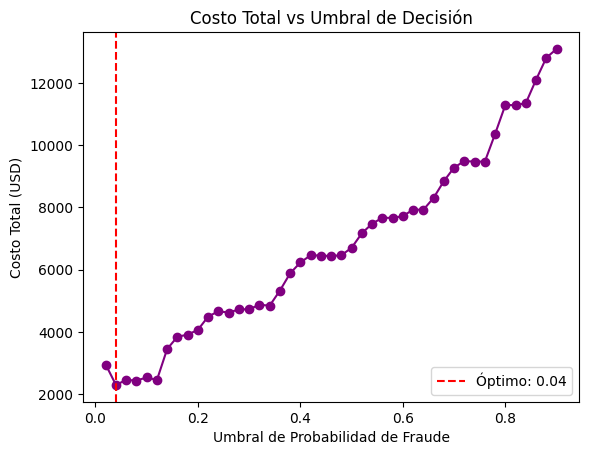

Costo si NO bloqueamos nada: $14,389.07
Costo si BLOQUEAMOS todo: $4,015.00
Costo con incertidumbre: Media $2,352.08
Intervalo Creíble 90%: [$2,156.91 - $2,573.12]


In [8]:
# ✏️ Función de costo, curva costo vs. umbral, políticas extremas y costo con 200 muestras de la posterior
# PARTE 4: DECISIÓN CON MATRIZ DE COSTOS E INCERTIDUMBRE

# 1. Obtener montos reales de las transacciones de prueba de forma segura
# uso el ratio de X_test y el ingreso de esas mismas filas en df
montos_test = X_test['ratio'] * df.loc[X_test.index, 'ingreso_mensual']

# 2. Evaluando umbrales
umbrales = np.arange(0.02, 0.92, 0.02)
costos = []

for u in umbrales:
    preds = (p_bayes >= u).astype(int)

    # Falsos Negativos: Es fraude (1) y no lo bloqueamos (0)
    fn = ((y_test == 1) & (preds == 0))
    # Falsos Positivos: No es fraude (0) y lo bloqueamos (1)
    fp = ((y_test == 0) & (preds == 1))

    # Costo total: Monto perdido por FN + USD 5 por FP
    costo_total = (fn * montos_test).sum() + (fp * 5).sum()
    costos.append(costo_total)

# 3. Ahora, para encontrar el umbral óptimo
umbral_optimo = umbrales[np.argmin(costos)]
costo_optimo = min(costos)

print(f"Umbral óptimo: {umbral_optimo:.2f}")
print(f"Costo mínimo en prueba: ${costo_optimo:,.2f}")

# 4. Gráfico de la curva de costo
plt.plot(umbrales, costos, marker='o', color='purple')
plt.axvline(umbral_optimo, color='red', linestyle='--', label=f'Óptimo: {umbral_optimo:.2f}')
plt.title('Costo Total vs Umbral de Decisión')
plt.xlabel('Umbral de Probabilidad de Fraude')
plt.ylabel('Costo Total (USD)')
plt.legend()
plt.show()

# 5. Políticas extremas
# No bloquear nada: Costo = suma de todos los montos de fraudes reales
costo_no_bloquear = (y_test * montos_test).sum()
# Bloquear todo: Costo = USD 5 por cada transacción legítima (falso positivo)
costo_bloquear_todo = ((y_test == 0) * 5).sum()

print(f"Costo si NO bloqueamos nada: ${costo_no_bloquear:,.2f}")
print(f"Costo si BLOQUEAMOS todo: ${costo_bloquear_todo:,.2f}")

# 6. Incertidumbre con 200 muestras de la posterior
costos_incert = []
for i in range(200):
    p_m = p_bayes_muestras[i] # Probabilidades de la muestra i
    preds_m = (p_m >= umbral_optimo).astype(int)

    fn_m = ((y_test == 1) & (preds_m == 0))
    fp_m = ((y_test == 0) & (preds_m == 1))

    costos_incert.append((fn_m * montos_test).sum() + (fp_m * 5).sum())

print(f"Costo con incertidumbre: Media ${np.mean(costos_incert):,.2f}")
print(f"Intervalo Creíble 90%: [${np.percentile(costos_incert, 5):,.2f} - ${np.percentile(costos_incert, 95):,.2f}]")

**✍️ Respuesta:** El análisis de la matriz de costos revela que el umbral óptimo de decisión es de 0.04. Con este umbral, el costo total en el conjunto de prueba se minimiza a $2,295.41.

Este resultado es interesante por lo siguiente. i), el umbral es muy bajo (4%), lo que indica que, dado el alto costo de perder el monto de una transacción fraudulenta en comparación con el bajo costo de molestar a un cliente legítimo (USD 5), la política óptima es ser muy conservador y bloquear ante la mínima sospecha. ii), si comparamos con las políticas extremas, se ve el valor del modelo: no bloquear nada tendría un costo catastrófico de $14,389.07, y bloquear absolutamente todo (incluso si el modelo dice 0% de probabilidad) costaría $4,015.00. El modelo permite ahorrar casi la mitad del dinero en comparación con bloquear a ciegas.

Finalmente, al incorporar la incertidumbre de las 200 muestras de la posterior, observamos que el costo esperado es de $2,352.08, con un intervalo creíble del 90% que va desde $2,156.91 hasta $2,573.12. Esto le da a las autoridades una visión realista: no importa qué muestra de la realidad tomemos, el costo siempre se mantendrá en un rango controlado, demostrando que la estrategia es robusta.

---
## Parte 5 · Informe ejecutivo (20 pts)
Para el **comité de riesgos** de PagoYa. Entre media y una página. Sin código: cifras de **sus** resultados.

### 1. Hallazgos
_(¿Qué variables explican el fraude? ¿Qué modelo ordena mejor y cuál está mejor calibrado? ¿Qué muestra el análisis por provincia?)_

El análisis desarrollado de las transacciones revela que el fraude (que tiene una tasa base del 10.65%) está influenciado por el comportamiento del usuario en el momento de la transacción. Las variables más críticas son el uso de un dispositivo nuevo (que multiplica las probabilidades de fraude por 2.51) y un ratio alto de monto frente al ingreso del usuario (multiplicador de 2.29).

Al comparar tecnologías, XGBoost demostró una ligera ventaja para ordenar los casos más sospechosos (AUC de 0.91 vs 0.86 del modelo bayesiano). Sin embargo, el modelo bayesiano demostró una calibración superior y más honesta. XGBoost, al ser ajustado para priorizar la detección, sobreestima el riesgo (prediciendo 91% donde la realidad es 70%). A nivel geográfico, el modelo jerárquico demostró que el fraude es un fenómeno homogéneo a nivel nacional (sigma de 0.078), siendo provincias con menos datos (como El Oro o Azuay) las que más se ajustan al promedio nacional para evitar conclusiones falsas.

### 2. Recomendación
_(Umbral recomendado, costo esperado e intervalo, ahorro frente a no hacer nada. ¿Qué modelo usaría en producción y para qué?)_

Se recomienda implementar el modelo bayesiano como el motor principal de decisión en producción, utilizando un umbral de bloqueo del 4%. Esta política es la más rentable: minimiza el costo esperado a $2,295 (con un intervalo de confianza del 90% entre $2,156 y $2,573). Esta estrategia representa un ahorro masivo frente a no hacer nada (que costaría $14,389 en pérdidas por fraude) y es más inteligente que bloquear todo a ciegas (que costaría $4,015 en fricción con clientes legítimos). Se sugiere usar XGBoost como un filtro secundario de priorización para los analistas humanos, pero las decisiones automáticas de bloqueo deben basarse en la probabilidad calibrada del bayesiano.

### 3. Limitaciones y riesgos
_(Datos simulados, variables faltantes, efecto no lineal de la hora, cambios de comportamiento del fraude, monitoreo necesario.)_

Este análisis se basa en datos históricos simulados; los patrones de los defraudadores cambiarán con el tiempo (concept drift o data drift). El modelo asume una relación lineal con la hora del día, lo cual es una limitación técnica (sería mejor categorizar la madrugada). Además, el umbral óptimo del 4% es estático; en el futuro, el sistema debería evolucionar hacia un umbral variable basado en el monto de cada transacción (a mayor monto, menor tolerancia al riesgo). Se requiere un monitoreo continuo (ciclo PDCA) y reentrenamiento mensual para asegurar que la calibración del modelo no se pierda.
